<a href="https://colab.research.google.com/github/aldwlsl/26-2-DIP-202302290/blob/main/HW01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 실습코드00: ITK-SNAP으로 day15를 day0에 registration을 진행한 결과파일을 불러와서 같은 단면을 day0, day15에 대해 display하여 비교하기

In [73]:
import numpy as np
import matplotlib.pyplot as plt

In [74]:
!pip install nibabel

In [75]:
import nibabel as nib
from google.colab import drive
drive.mount('/content/drive')
import os
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [76]:
ct_FU = nib.load('/content/drive/MyDrive/DIP4E/volume-covid19-A-0700_day000.nii.gz').get_fdata()
ct_FU_reg = nib.load('/content/drive/MyDrive/DIP4E/registration.nii.gz').get_fdata()
h = nib.load('/content/drive/MyDrive/DIP4E/volume-covid19-A-0700_day015.nii.gz')

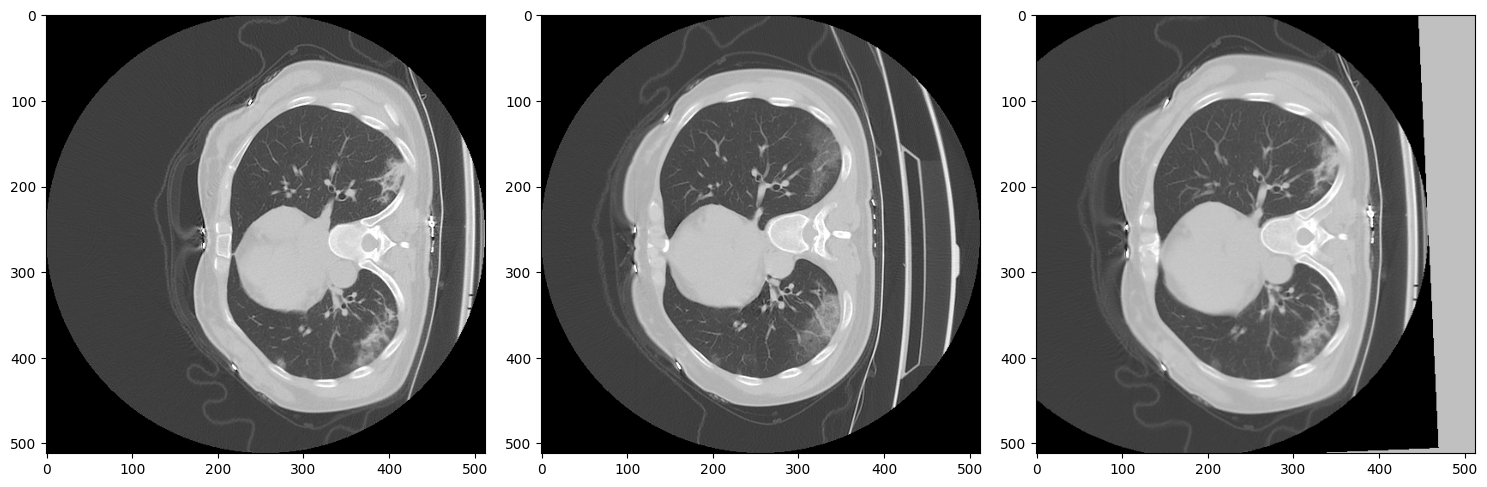

In [77]:
ct_base = h.get_fdata()
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

# 2. 실습코드01: Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기



In [78]:
import cv2

In [83]:
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'

In [84]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

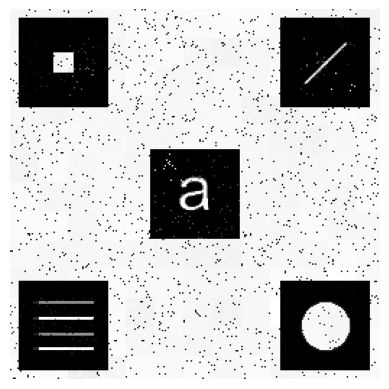

In [91]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
N = 20

f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

# 3. 실습코드01: Exercise 2. 본인의 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

In [114]:
import time
import scipy.signal as signal

In [120]:
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/'

f = plt.imread(imgpath+'IMG_9346.jpeg')
print(f.shape,f.dtype)
f=  cv2.cvtColor(f, cv2.COLOR_RGB2GRAY) / 255.0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(3024, 4032, 3) uint8


computation time =  0.7785861492156982  sec


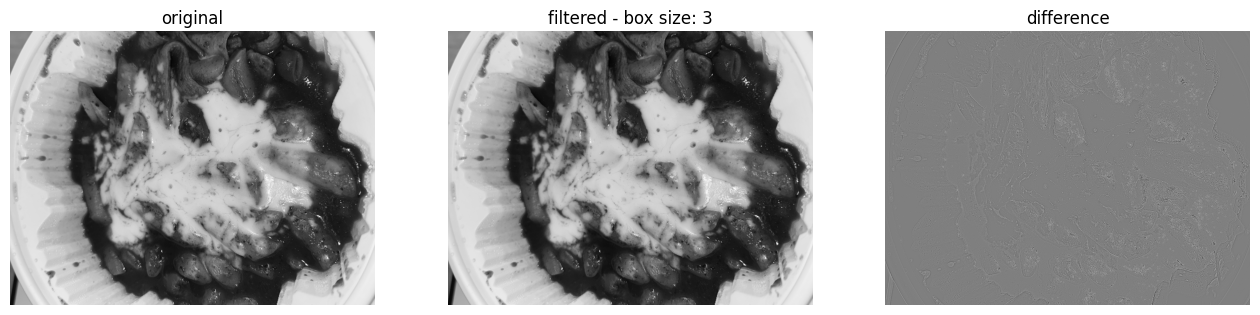

computation time =  1.4680655002593994  sec


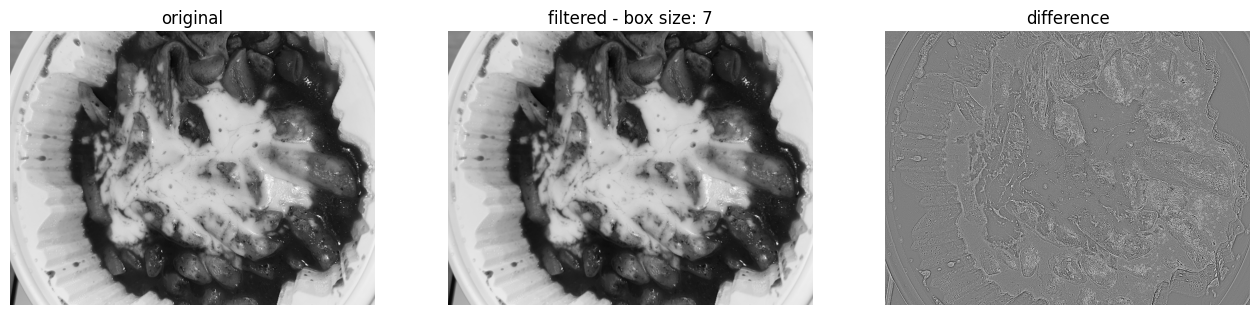

computation time =  5.261500835418701  sec


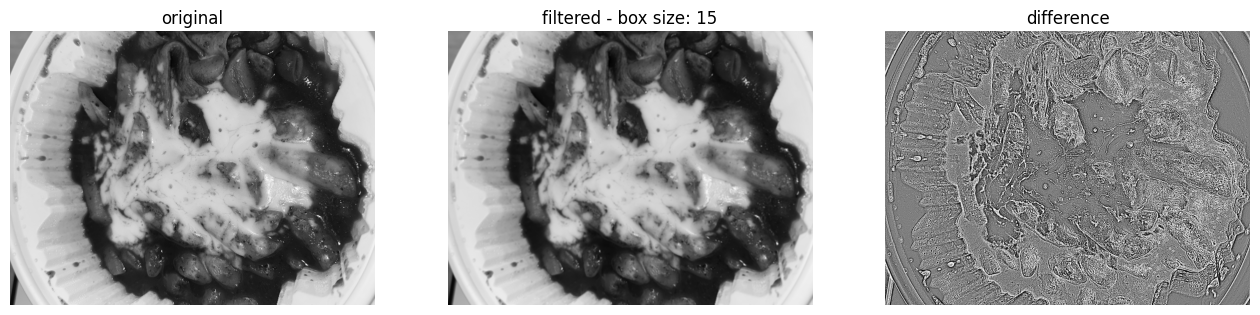

computation time =  21.408480644226074  sec


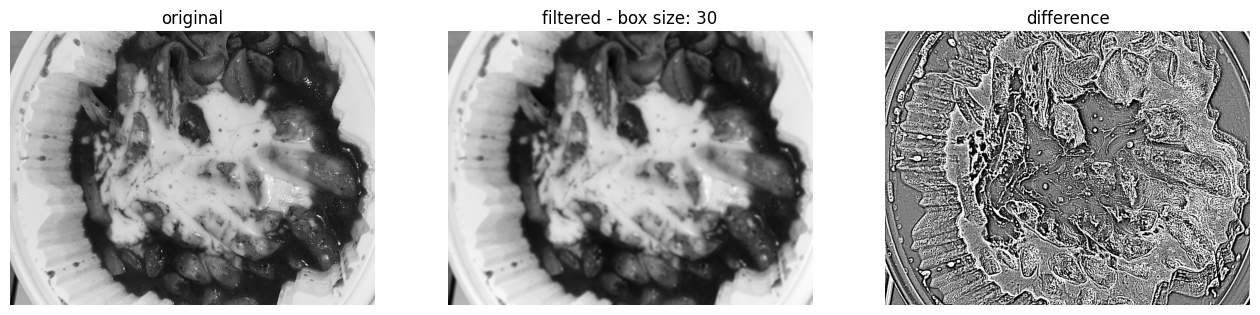

In [126]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same',boundary='symm')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

# 4. 실습코드01: Exercise 3. Blurring이 발생한 사진을 가져와서 적당한 HPF결과를 활용하여 sharpening을 진행하기

In [132]:
from skimage import io
import os

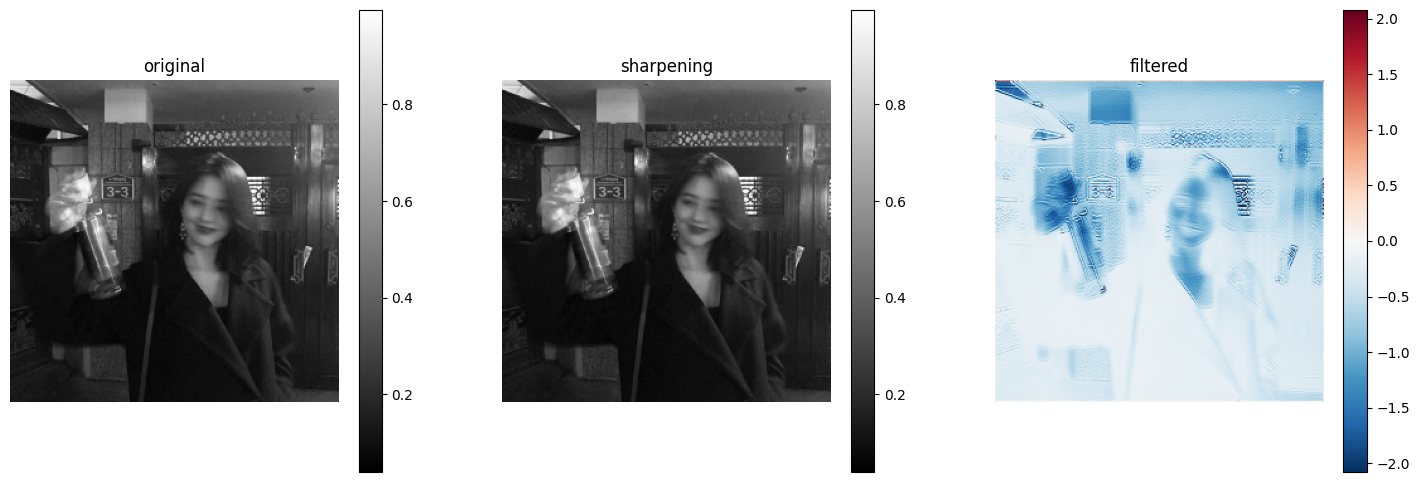

In [146]:

f = io.imread('https://search.pstatic.net/common/?src=http%3A%2F%2Fcafefiles.naver.net%2FMjAyMDA1MDRfMTc4%2FMDAxNTg4NTc3MDY5NjYz.pF6G0UcXacF03bGvEi-sz7brruBvnP-BZjseE04shskg.rIBlwT-Xz5EYs1bO1ws9IH4buE79XDSOJ7qsn6hm9xcg.JPEG%2FexternalFile.jpg&type=sc960_832',as_gray=True)[::2,::2]

w = np.array([[0,-2,0],[-1,5.,-1],[0,-3,0]])
y = signal.convolve2d(f,w,mode='same')
c = 0.0000002
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()